# Activity 6.03 — Creating a Stacked Bar Plot for Restaurant Performance

**Student:** LU MENGJIE (MC643920)  
**Purpose:** Use Seaborn’s standard tips sample (included locally) to compare daily restaurant bills by smoker status.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
from pathlib import Path

def locate_datasets():
    here = Path.cwd().resolve()
    for folder in (here, *here.parents):
        candidate = folder / "Datasets"
        if candidate.is_dir():
            return candidate
    raise FileNotFoundError("Could not find the project Datasets folder.")

DATASETS = locate_datasets()
print("Datasets:", DATASETS)

Datasets: C:\Users\22392\Desktop\cisc7204_sugex06_mc643920\Submission\cisc7204_sugex06_MC643920\Datasets


In [2]:
# Local copy of Seaborn's standard tips sample keeps this notebook runnable offline.
tips = pd.read_csv(DATASETS / 'tips.csv')
sns.set_theme(style='whitegrid')
daily = tips.pivot_table(index='day', columns='smoker', values='total_bill', aggfunc='sum')
days = ['Thur', 'Fri', 'Sat', 'Sun']
daily = daily.reindex(days)
daily

smoker,No,Yes
day,,
Thur,770.09,326.24
Fri,73.68,252.20
Sat,884.78,893.62
Sun,1168.88,458.28


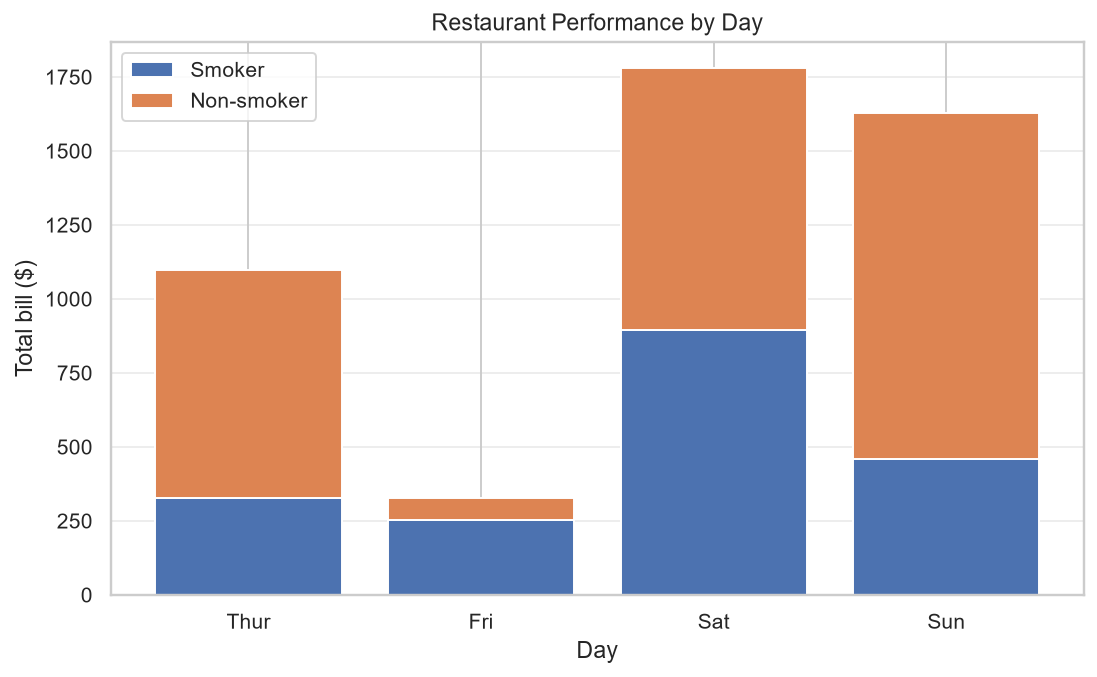

In [3]:
fig, ax = plt.subplots(figsize=(8, 5), dpi=140)
ax.bar(days, daily['Yes'], label='Smoker')
ax.bar(days, daily['No'], bottom=daily['Yes'], label='Non-smoker')
ax.set_xlabel('Day')
ax.set_ylabel('Total bill ($)')
ax.set_title('Restaurant Performance by Day')
ax.legend()
ax.grid(axis='y', alpha=0.35)
fig.tight_layout()
plt.show()